In [1]:
import requests
import xarray as xr
import torch
import os
import numpy as np
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import matplotlib
import matplotlib.pyplot as plt

In [ ]:
dataset = xr.open_zarr("gs://gcp-public-data-arco-era5/ar/full_37-1h-0p25deg-chunk-1.zarr-v3", chunks=None)
# dataset = dataset[["2m_temperature"]]
# dataset = dataset.sel(time=slice("2023-10-31", "2024-10-31"))

print(dataset["longitude"])
print(dataset["latitude"])
print('-----------------------------------------------------')
# convert latitude and longitude to -90 to 90 and -180 to 180 respectively
if dataset["longitude"].max() > 180:
     dataset = dataset.assign_coords(longitude=(dataset["longitude"].values + 180) % 360 - 180)
if dataset["latitude"].max() > 90:
    dataset = dataset.assign_coords(latitude=dataset["latitude"].values - 90)

print(dataset["longitude"])
print(dataset["latitude"])
print('-----------------------------------------------------')
dataset = dataset.sortby(["latitude", "longitude"])
dataset = dataset.chunk()

print(dataset["longitude"])
print(dataset["latitude"])
print('-----------------------------------------------------')

<xarray.DataArray 'longitude' (longitude: 1440)>
array([0.0000e+00, 2.5000e-01, 5.0000e-01, ..., 3.5925e+02, 3.5950e+02,
       3.5975e+02], dtype=float32)
Coordinates:
  * longitude  (longitude) float32 0.0 0.25 0.5 0.75 ... 359.0 359.2 359.5 359.8
Attributes:
    long_name:  longitude
    units:      degrees_east
<xarray.DataArray 'latitude' (latitude: 721)>
array([ 90.  ,  89.75,  89.5 , ..., -89.5 , -89.75, -90.  ], dtype=float32)
Coordinates:
  * latitude  (latitude) float32 90.0 89.75 89.5 89.25 ... -89.5 -89.75 -90.0
Attributes:
    long_name:  latitude
    units:      degrees_north
-----------------------------------------------------
<xarray.DataArray 'longitude' (longitude: 1440)>
array([ 0.  ,  0.25,  0.5 , ..., -0.75, -0.5 , -0.25], dtype=float32)
Coordinates:
  * longitude  (longitude) float32 0.0 0.25 0.5 0.75 ... -1.0 -0.75 -0.5 -0.25
<xarray.DataArray 'latitude' (latitude: 721)>
array([ 90.  ,  89.75,  89.5 , ..., -89.5 , -89.75, -90.  ], dtype=float32)
Coordinates:
  *

In [8]:
ds = xr.open_zarr(
    "gs://gcp-public-data-arco-era5/ar/full_37-1h-0p25deg-chunk-1.zarr-v3",
    chunks=None,
    storage_options=dict(token="anon")
)

print(list(ds.data_vars))

['100m_u_component_of_wind', '100m_v_component_of_wind', '10m_u_component_of_neutral_wind', '10m_u_component_of_wind', '10m_v_component_of_neutral_wind', '10m_v_component_of_wind', '10m_wind_gust_since_previous_post_processing', '2m_dewpoint_temperature', '2m_temperature', 'air_density_over_the_oceans', 'angle_of_sub_gridscale_orography', 'anisotropy_of_sub_gridscale_orography', 'benjamin_feir_index', 'boundary_layer_dissipation', 'boundary_layer_height', 'charnock', 'clear_sky_direct_solar_radiation_at_surface', 'cloud_base_height', 'coefficient_of_drag_with_waves', 'convective_available_potential_energy', 'convective_inhibition', 'convective_precipitation', 'convective_rain_rate', 'convective_snowfall', 'convective_snowfall_rate_water_equivalent', 'downward_uv_radiation_at_the_surface', 'duct_base_height', 'eastward_gravity_wave_surface_stress', 'eastward_turbulent_surface_stress', 'evaporation', 'forecast_albedo', 'forecast_logarithm_of_surface_roughness_for_heat', 'forecast_surface

In [9]:
dataset["2m_temperature"]

<xarray.DataArray '2m_temperature' (time: 8808, latitude: 721, longitude: 1440)>
dask.array<xarray-2m_temperature, shape=(8808, 721, 1440), dtype=float32, chunksize=(8808, 721, 1440), chunktype=numpy.ndarray>
Coordinates:
  * latitude   (latitude) float32 -90.0 -89.75 -89.5 -89.25 ... 89.5 89.75 90.0
  * longitude  (longitude) float32 -180.0 -179.8 -179.5 ... 179.2 179.5 179.8
  * time       (time) datetime64[ns] 2023-10-31 ... 2024-10-31T23:00:00
Attributes:
    long_name:   2 metre temperature
    short_name:  t2m
    units:       K

In [10]:
MONTHS = ["2023-10", "2023-11", "2023-12", "2024-01", "2024-02", "2024-03", "2024-04", "2024-05", "2024-06", "2024-07", "2024-08", "2024-09", "2024-10"]
WRITE_FILES = False

In [ ]:
absolute_max = 0
stored_difficulties = []
for i, start in enumerate(MONTHS[:-1]):
    end = MONTHS[i+1]
    month_data = dataset.sel(time=slice(start, end))

    # fetch that data -- takes 1-2 minutes per call
    month_data = month_data.compute()

    # calculate the 'variance of time-derivative' for each location
    t2m_data = torch.as_tensor(month_data["2m_temperature"].data, dtype=torch.float)
    t2m_diffs = torch.diff(t2m_data, n=1, dim=0)
    var_per_loc = t2m_diffs.var(dim=0)

    month_str = start.split('-')[-1]
    print(f"Min/Mean/Max for {month_str}", var_per_loc.min(), var_per_loc.mean(), var_per_loc.max())

    if var_per_loc.max() > absolute_max:
        absolute_max = var_per_loc.max()
    
    stored_difficulties.append((month_str, var_per_loc.numpy()))

    print(var_per_loc.shape)

    
if WRITE_FILES:
    for month_str, var_per_loc in stored_difficulties:
        var_per_loc = var_per_loc / absolute_max
        np.save(f"../data/weights/difficulty_{month_str}_grid_025.npy", var_per_loc.numpy())

Min/Mean/Max for 10 tensor(0.0029) tensor(0.3871) tensor(8.6252)
torch.Size([721, 1440])
Min/Mean/Max for 11 tensor(0.0032) tensor(0.3710) tensor(8.4370)
torch.Size([721, 1440])


In [8]:
# create artificial grid of latitudes and longitudes for plotting
x_grid = torch.stack(
    torch.meshgrid(
        *[
            torch.as_tensor(
                dataset[v].data, dtype=torch.float
            )
            for v in ("latitude", "longitude")
        ],
        indexing="ij",
    ),
    dim=-1,
)

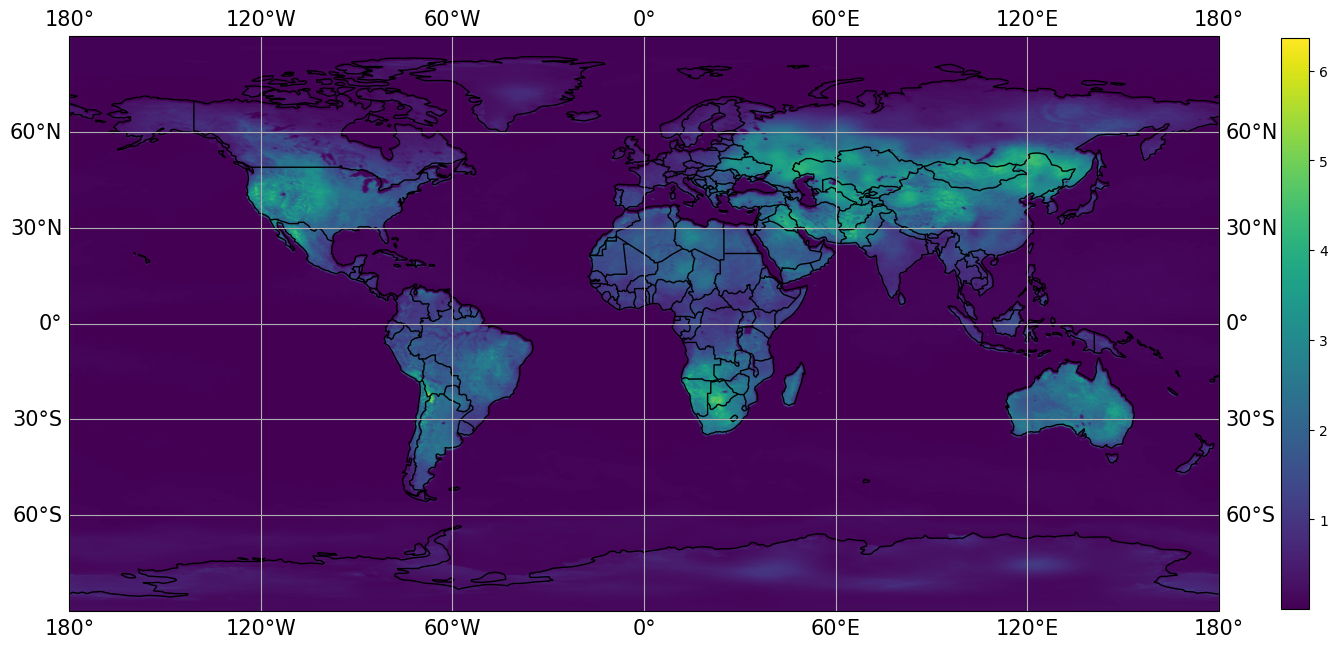

In [10]:
# plot the last month's data
fig = plt.figure(figsize=(16.0, 12.0), dpi=100)

ax = plt.axes(projection=ccrs.PlateCarree())
ax.add_feature(cfeature.COASTLINE)
ax.add_feature(cfeature.BORDERS)
ax.set_axisbelow(True)

gl = ax.gridlines(draw_labels=True)
gl.xlabel_style = {"size": 15}
gl.ylabel_style = {"size": 15}
scatterplot = ax.scatter(
        x_grid[..., -1], 
        x_grid[..., -2], 
        c=var_per_loc, 
        s= 10,
        marker= "o",
        lw= 0, 
)

cbar = fig.colorbar(scatterplot, ax=ax, fraction=0.023, pad=0.05)
plt.show()